# Second-stage feature distributions by class

This notebook plots one combined set of violin distributions for every annotated cell listed in the second-stage train, validation, and test splits. Matrix values are loaded directly from `Data/Raw/beach_all`.

Features: `r` = red, `g` = green, `b` = blue, `s` = slope, and `d` = elevation. NaN, infinite, and exact `-999` values are treated as missing and replaced with the corresponding mean calculated from training cells only. Each violin includes the class mean and one standard deviation error bars. No pixel sampling cap is applied.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (
    (PROJECT_ROOT / "Source").exists()
    or (PROJECT_ROOT / "Data").exists()
    or (PROJECT_ROOT / "pmaciag-volume-beach").exists()
):
    PROJECT_ROOT = PROJECT_ROOT.parent
if (PROJECT_ROOT / "pmaciag-volume-beach").exists():
    PROJECT_ROOT = PROJECT_ROOT / "pmaciag-volume-beach"
if not ((PROJECT_ROOT / "Source").exists() or (PROJECT_ROOT / "Data").exists()):
    raise RuntimeError("Could not locate pmaciag-volume-beach project directory.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from Source.beach_dataset import (
    FEATURE_SUFFIXES,
    compute_channel_stats,
    load_cell_array,
    make_class_mapping,
    read_class_name_mapping,
    read_split_csv,
)

/Users/piotr/Praca/Nauka/publikacje/Beach_classification/Beach_classification_software/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
CELL_DATA_ROOT = PROJECT_ROOT / "Data" / "Raw" / "beach_all"
CLASS_MAPPING_PATH = PROJECT_ROOT / "Data" / "Raw" / "grainsize_spec.xlsx"
SPLIT_PATH = PROJECT_ROOT / "Data" / "Preprocessed" / "ss_dataset_splits.csv"

FEATURE_LABELS = {
    "r": "red channel (r)",
    "g": "green channel (g)",
    "b": "blue channel (b)",
    "s": "slope (s)",
    "d": "elevation (d)",
}
FEATURE_COLORS = {
    "r": "#d62728",
    "g": "#2ca02c",
    "b": "#1f77b4",
    "s": "#9467bd",
    "d": "#ff7f0e",
}
EXPECTED_SPLITS = {"train", "validation", "test"}

print(f"Cell data: {CELL_DATA_ROOT}")
print(f"Split file: {SPLIT_PATH}")

Cell data: /Users/piotr/Praca/Nauka/publikacje/Beach_classification/Beach_classification_software/pmaciag-volume-beach/Data/Raw/beach_all
Split file: /Users/piotr/Praca/Nauka/publikacje/Beach_classification/Beach_classification_software/pmaciag-volume-beach/Data/Preprocessed/ss_dataset_splits.csv


In [3]:
if not CELL_DATA_ROOT.exists():
    raise FileNotFoundError(f"Cell data directory not found: {CELL_DATA_ROOT}")

all_labeled_data = read_split_csv(SPLIT_PATH)
if "split" not in all_labeled_data.columns:
    raise ValueError(f"Split column is missing from {SPLIT_PATH}")
actual_splits = set(all_labeled_data["split"].astype(str))
if actual_splits != EXPECTED_SPLITS:
    raise ValueError(f"Expected splits {sorted(EXPECTED_SPLITS)}, got {sorted(actual_splits)}")
if all_labeled_data.duplicated(["date", "cell_id"]).any():
    raise ValueError("Duplicate date/cell_id entries found in the combined split file.")

training_data = all_labeled_data.loc[all_labeled_data["split"] == "train"].copy()
class_to_idx = make_class_mapping(all_labeled_data)
class_name_by_code = read_class_name_mapping(CLASS_MAPPING_PATH, class_to_idx.keys())
class_codes = [code for code, _ in sorted(class_to_idx.items(), key=lambda item: item[1])]
class_labels = [
    f"{code}: {class_name_by_code.get(code, f'class_{code}')}"
    for code in class_codes
]

channel_mean, channel_std = compute_channel_stats(
    training_data,
    CELL_DATA_ROOT,
    FEATURE_SUFFIXES,
)
channel_mean_by_feature = dict(zip(FEATURE_SUFFIXES, channel_mean))

display(all_labeled_data.groupby("split").size().rename("cells").to_frame())
display(all_labeled_data.groupby("class").size().rename("cells").to_frame())
display(
    pd.DataFrame({
        "feature": FEATURE_SUFFIXES,
        "training_mean_used_for_missing_values": channel_mean,
        "training_std": channel_std,
    })
)

,cells
split,
test,21
train,98
validation,21


,cells
class,
11,22
12,64
13,54


,feature,training_mean_used_for_missing_values,training_std
0,r,162.305893,30.699274
1,g,169.978363,32.131519
2,b,180.470947,32.565948
3,s,11.549057,7.687606
4,d,0.999458,0.748065


In [9]:
def collect_feature_values(frame):
    buckets = {
        feature: {class_code: [] for class_code in class_codes}
        for feature in FEATURE_SUFFIXES
    }
    rows = frame[["date", "cell_id", "class"]].itertuples(index=False, name=None)
    for date, cell_id, class_code in tqdm(rows, total=len(frame), desc="Loading labeled cells"):
        array = load_cell_array(CELL_DATA_ROOT, date, cell_id, FEATURE_SUFFIXES)
        class_code = str(class_code)
        for feature_index, feature in enumerate(FEATURE_SUFFIXES):
            values = array[feature_index].reshape(-1)
            values = np.where(
                np.isfinite(values),
                values,
                channel_mean_by_feature[feature],
            )
            buckets[feature][class_code].extend(values.astype(float).tolist())
    return buckets


def plot_combined_violins(buckets):
    fig, axes = plt.subplots(
        nrows=len(FEATURE_SUFFIXES),
        ncols=1,
        figsize=(max(6, len(class_codes) * 1.2), 3.2 * len(FEATURE_SUFFIXES)),
        sharex=True,
    )
    positions = np.arange(1, len(class_codes) + 1)
    for axis, feature in zip(axes, FEATURE_SUFFIXES):
        data = [buckets[feature][class_code] for class_code in class_codes]
        nonempty = [(position, values) for position, values in zip(positions, data) if values]
        if nonempty:
            nonempty_positions = [position for position, _ in nonempty]
            nonempty_data = [values for _, values in nonempty]
            parts = axis.violinplot(
                nonempty_data,
                positions=nonempty_positions,
                showmeans=False,
                showmedians=True,
                showextrema=False,
            )
            for body in parts["bodies"]:
                body.set_facecolor(FEATURE_COLORS[feature])
                body.set_edgecolor("black")
                body.set_alpha(0.65)
            means = np.array([np.mean(values) for values in nonempty_data])
            standard_deviations = np.array([np.std(values) for values in nonempty_data])
            axis.errorbar(
                nonempty_positions,
                means,
                yerr=standard_deviations,
                fmt="o",
                color="black",
                ecolor="black",
                elinewidth=1.1,
                capsize=3,
                markersize=4,
            )
            if "cmedians" in parts:
                parts["cmedians"].set_color("black")
        axis.set_ylabel(FEATURE_LABELS[feature])
        axis.set_title(FEATURE_LABELS[feature])
        axis.grid(axis="y", alpha=0.25)

    axes[-1].set_xticks(positions)
    axes[-1].set_xticklabels(class_labels, rotation=45, ha="right")
    axes[-1].set_xlabel("Class")
    fig.suptitle(
        "All second-stage labeled cells: feature distributions by class\n"
        "Missing values use training means; bars show mean +/- 1 std",
        y=1.01,
    )
    fig.tight_layout()
    return fig

Loading labeled cells: 100%|██████████| 140/140 [00:00<00:00, 743.42it/s]


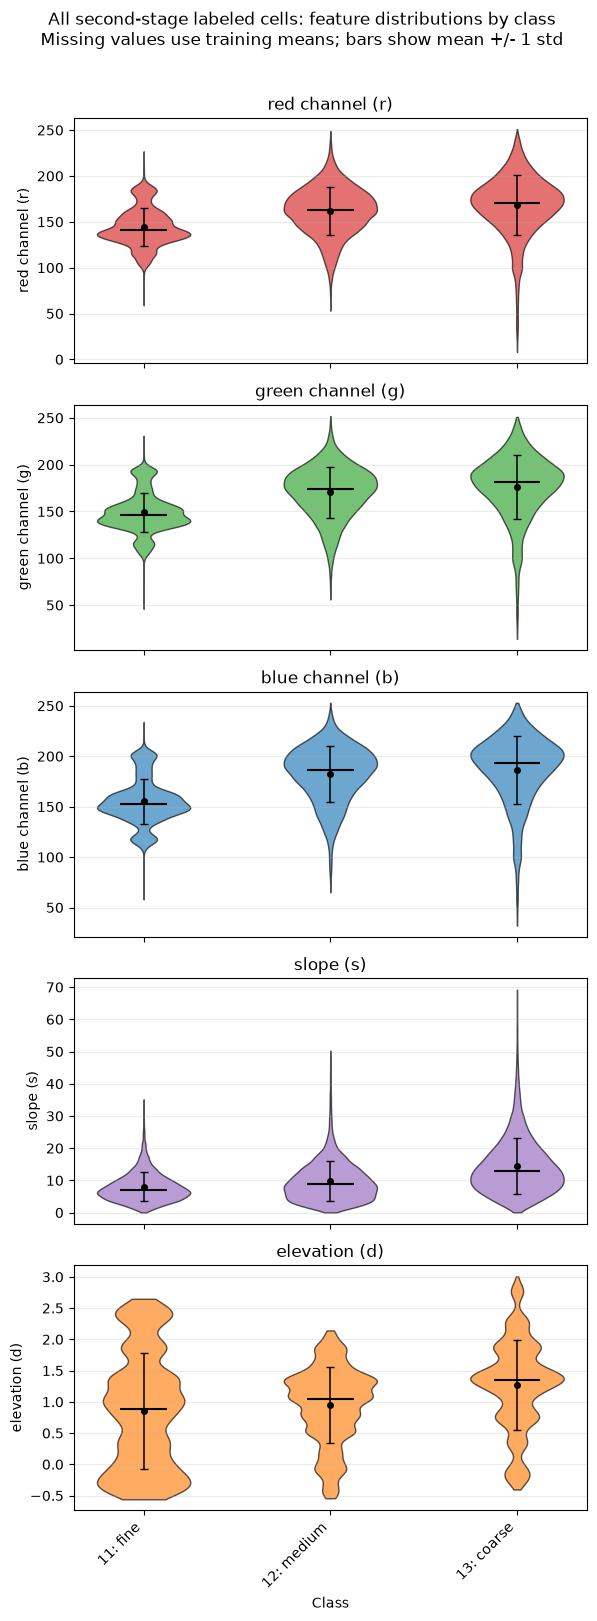

In [10]:
combined_buckets = collect_feature_values(all_labeled_data)
combined_figure = plot_combined_violins(combined_buckets)
plt.show()

In [11]:
OUTLIER_THRESHOLD = -900

# Exact -999 values are converted to NaN by load_cell_array and are therefore
# imputed in the violin plot. This report finds remaining finite values near -1000.
outlier_rows = []
rows = all_labeled_data[["split", "date", "cell_id", "class"]].itertuples(
    index=False,
    name=None,
)
for split, date, cell_id, class_code in tqdm(
    rows,
    total=len(all_labeled_data),
    desc="Checking slope/elevation outliers",
):
    array = load_cell_array(CELL_DATA_ROOT, date, cell_id, FEATURE_SUFFIXES)
    slope = array[FEATURE_SUFFIXES.index("s")]
    elevation = array[FEATURE_SUFFIXES.index("d")]
    slope_pixels = int((np.isfinite(slope) & (slope <= OUTLIER_THRESHOLD)).sum())
    elevation_pixels = int((np.isfinite(elevation) & (elevation <= OUTLIER_THRESHOLD)).sum())
    if slope_pixels or elevation_pixels:
        class_code = str(class_code)
        outlier_rows.append({
            "split": split,
            "date": date,
            "cell_id": cell_id,
            "class": class_code,
            "class_name": class_name_by_code.get(class_code, f"class_{class_code}"),
            "slope_outlier_pixels": slope_pixels,
            "elevation_outlier_pixels": elevation_pixels,
            "total_outlier_pixels": slope_pixels + elevation_pixels,
        })

outlier_cells = pd.DataFrame(outlier_rows)
slope_total = int(outlier_cells["slope_outlier_pixels"].sum()) if not outlier_cells.empty else 0
elevation_total = int(outlier_cells["elevation_outlier_pixels"].sum()) if not outlier_cells.empty else 0
print(f"Outlier threshold: <= {OUTLIER_THRESHOLD}")
print(f"Cells with slope/elevation outliers: {len(outlier_cells):,}")
print(f"Slope outlier pixels: {slope_total:,}")
print(f"Elevation outlier pixels: {elevation_total:,}")
print(f"Total outlier pixels: {slope_total + elevation_total:,}")
if not outlier_cells.empty:
    display(outlier_cells.sort_values(["date", "cell_id"]).reset_index(drop=True))
    print("Cell IDs:")
    print(", ".join(outlier_cells["cell_id"].astype(str).tolist()))

Checking slope/elevation outliers: 100%|██████████| 140/140 [00:00<00:00, 1250.47it/s]

Outlier threshold: <= -900
Cells with slope/elevation outliers: 0
Slope outlier pixels: 0
Elevation outlier pixels: 0
Total outlier pixels: 0
